# Más allá: el tamaño y la potencia de cada prueba, medidos sobre defectos plantados

**Pregunta:** ¿Mide el estudio el tamaño y la potencia de las pruebas de validación del motor sobre defectos plantados de verdad conocida, como afirma BS-1, y qué encontró la medición que un validador no aprendería del estándar ni de las herramientas?

- **Nivel:** 4, Más allá del estado del arte
- **Requisitos previos:** los notebooks 01 a 07 de este tema (las mediciones, y el estado del arte frente al que se ponen)
- **Tiempo de lectura:** unos 60 minutos

## Objetivos

Al terminar este notebook puedes:

- enunciar la afirmación BS-1 y la extensión de la evidencia que la respalda, contada sobre las ocho familias del caso C22;
- medir en vivo, con los estudios propios del motor, el tamaño y la potencia de pruebas de familias que los notebooks de crédito no cubren;
- contrastar cada probabilidad de rechazo exacta con su tasa simulada mediante la regla `agrees` del motor;
- repetir una fila de cada familia desde su semilla y ver la misma tasa;
- listar los defectos de pruebas estándar que halló la medición, con la cifra que evidencia cada uno, y decir hasta dónde llega la afirmación.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import os

# la generación fija sus hilos de cálculo (decisión D16-18): BLAS suma una cuadratura según los hilos
for _var in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[_var] = "4"

import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son las ocho familias del caso C22, validar al validador: `null`, `miscalibration`, `clustering`, `drift`, `discrimination-decay`, `leakage`, `broken-monotonicity` y `concentration`. Cada conjunto de ellas lo sortea un generador de verdad conocida de `riskvalidation.generators` (licencia MIT, clase `generated`), así que nada aquí es dato real de una cartera y cada número es una propiedad de esos generadores y de sus supuestos.

- **Archivos que se leen:** `data/derived/C22/<familia>.json` de las ocho familias: `outputs.simulations` (cada fila una prueba, una severidad, tasas con errores, la probabilidad exacta donde existe, la semilla), `outputs.panels` (si un panel mide tamaño o potencia), `outputs.generators` (configuración y verdad), `findings` y `provenance`.
- **No se leen:** `models-generators.json`, que describe los modelos de los generadores para la web, y `other-families.json`.

La celda siguiente carga los ocho archivos e imprime la versión del motor que calculó cada uno junto a la instalada.

In [2]:
# Cargar las ocho familias del caso C22 e indexar sus simulaciones
LANG = "es"
ROOT = Path("../../..").resolve()
names = ("null", "miscalibration", "clustering", "drift", "discrimination-decay", "leakage",
         "broken-monotonicity", "concentration")
families = {}
for n in names:
    path = ROOT / "data" / "derived" / "C22" / f"{n}.json"
    families[n] = json.loads(path.read_text(encoding="utf-8"))
rows = {n: {row["key"]: row for row in fam["outputs"]["simulations"]} for n, fam in families.items()}
for n in names:
    print(f"{n:22s} calculado con riskvalidation {families[n]['provenance']['riskvalidation_version']}")
print("instalado:", rv.__version__)

null                   calculado con riskvalidation 1.0.1
miscalibration         calculado con riskvalidation 1.0.1
clustering             calculado con riskvalidation 1.0.1
drift                  calculado con riskvalidation 1.0.1
discrimination-decay   calculado con riskvalidation 1.0.1
leakage                calculado con riskvalidation 1.0.1
broken-monotonicity    calculado con riskvalidation 1.0.1
concentration          calculado con riskvalidation 1.0.1
instalado: 1.0.1


## Método

El desempeño de una prueba se mide como en Morris, White y Crowther (2019): una tasa de rechazo es una estimación, informada con su error estándar de Monte Carlo $\sqrt{\hat r(1-\hat r)/n}$ y, aquí, el intervalo de Wilson que recomiendan Brown, Cai y DasGupta (2001). El tamaño es la tasa cuando se cumple la nula y la potencia la tasa cuando hay un defecto de severidad conocida; cada panel de un archivo dice cuál de los dos mide. Los pasos usan las funciones propias del motor, `simulate_study`, `Rate`, `agrees`, `simulate` y los generadores, y no les agregan nada.

## Estado del arte

Lo que el estándar, la literatura y las herramientas ofrecían a un validador, según expone el notebook 07:

- **Las instrucciones del BCE (2019)** definen los estadísticos y los valores p de las pruebas que implementa el motor y no fijan umbrales de aprobación, que quedan a cargo de la institución. Un validador que las aplica debe elegir un umbral, y nada en las instrucciones dice con qué frecuencia la prueba dará una falsa alarma o dejará pasar un defecto.
- **El documento de trabajo 14 de BCBS (2005)** simuló dos pruebas de calibración y concluyó que «at present no really powerful tests of adequate calibration are currently available».
- **Yurdakul y Naranjo (2020)** observaron que las bandas de 0,10 y 0,25 del PSI se «used without reference to statistical type I or type II error rates», y las midieron en un diseño.
- **Demler et al. (2012)** midieron una prueba, DeLong en modelos anidados, en un diseño.
- **Las herramientas de validación** que relevó la investigación listan pruebas, umbrales y semáforos, y no registraron tamaño ni potencia medidos para ninguna (NO VERIFICADO más allá de la documentación que leyó).

Así, el estado del arte midió un puñado de pruebas, un diseño a la vez, con los supuestos de las propias pruebas; nada de lo que halló la investigación midió todas las pruebas de un motor bajo los mismos defectos plantados, con el error de Monte Carlo de cada tasa.

## Más allá del estado del arte

**Afirmación BS-1: el tamaño y la potencia medidos de las pruebas de validación sobre defectos plantados.** Para cada prueba con valor p, Contraste informa su tasa de rechazo bajo la nula al 5 % y al 1 % y, para las pruebas con un defecto plantado que detectar, su tasa de rechazo frente a defectos de severidad conocida, cada tasa con su error estándar de Monte Carlo e intervalo de Wilson, sobre generadores cuya verdad es conocida. La afirmación se enuncia solo hasta donde llegan los archivos versionados, y los pasos siguientes miden esa extensión antes de decir nada sobre ella:

1. el inventario de simulaciones, repeticiones, pruebas y tasas, y para qué se midió cada prueba;
2. una medición en vivo de tamaño y potencia para pruebas de otras familias;
3. si las probabilidades exactas concuerdan con las tasas simuladas;
4. si las filas se repiten desde sus semillas;
5. lo que la medición halló en pruebas estándar, y el registro de hallazgos.

### Paso 1: el inventario

La celda siguiente cuenta, en los ocho archivos, las simulaciones, las repeticiones, las pruebas distintas, las tasas, las filas que llevan una probabilidad exacta y los generadores, y cuenta para cada prueba sus filas que miden tamaño y sus filas que miden potencia. Una barra apilada por prueba dibuja la extensión de la medición.

simulaciones: 256 | repeticiones: 651000
pruebas distintas: 42 | tasas: 537 | filas exactas: 47
generadores con verdad escrita: 148
pruebas con fila de tamaño y sin fila de potencia: 25


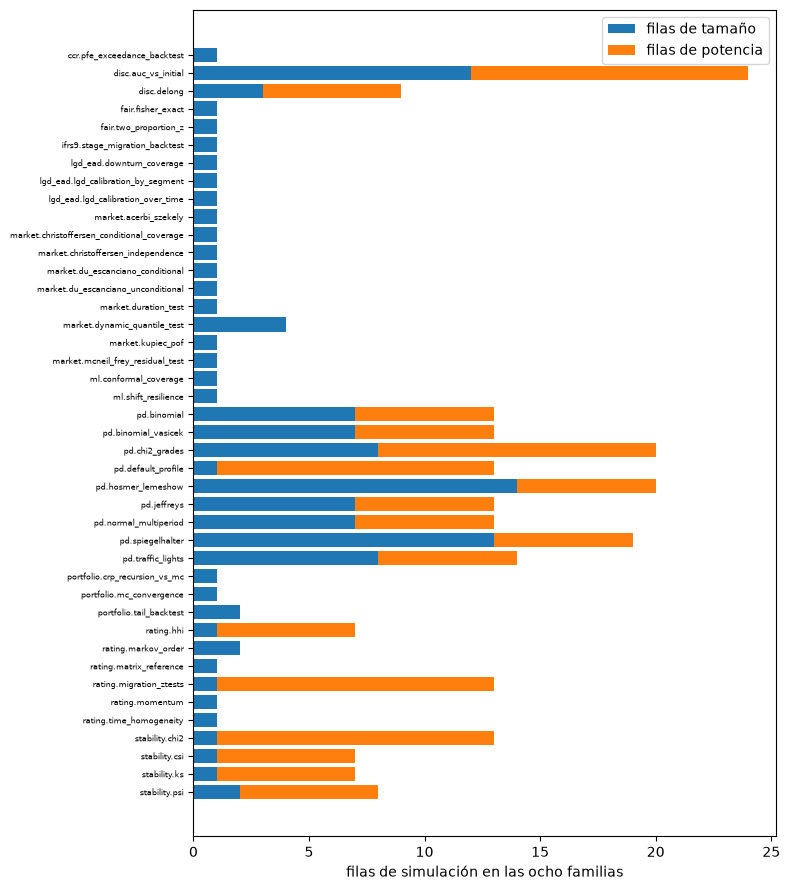

In [3]:
# Contar simulaciones, repeticiones, pruebas, tasas y filas exactas, y dibujar lo medido para cada prueba
from collections import Counter

coverage = {}
rates = exact_rows = generators = 0
for n in names:
    measures = {p["id"]: p["measures"] for p in families[n]["outputs"]["panels"]}
    generators += len(families[n]["outputs"]["generators"])
    for s in rows[n].values():
        entry = coverage.setdefault(s["test_id"], Counter())
        entry[measures[s["panel"]]] += 1
        rates += len(s["rates"])
        exact_rows += s["exact"] is not None
total = sum(len(rows[n]) for n in names)
print("simulaciones:", total, "|", "repeticiones:", sum(s["n_rep"] for n in names for s in rows[n].values()))
print("pruebas distintas:", len(coverage), "| tasas:", rates, "| filas exactas:", exact_rows)
print("generadores con verdad escrita:", generators)
print("pruebas con fila de tamaño y sin fila de potencia:", sum(1 for e in coverage.values() if e["power"] == 0))
tests = sorted(coverage)
fig, ax = plt.subplots(figsize=(8, 9))
size_rows = [coverage[t]["size"] for t in tests]
power_rows = [coverage[t]["power"] for t in tests]
ax.barh(range(len(tests)), size_rows, color="tab:blue", label="filas de tamaño")
ax.barh(range(len(tests)), power_rows, left=size_rows, color="tab:orange", label="filas de potencia")
ax.set_yticks(range(len(tests)))
ax.set_yticklabels(tests, fontsize=6)
ax.invert_yaxis()
ax.set_xlabel("filas de simulación en las ocho familias")
ax.legend()
fig.tight_layout()
plt.show()

Los ocho archivos reúnen 256 simulaciones y 651.000 repeticiones con semilla de 42 pruebas distintas, 537 tasas en total, 47 filas con una probabilidad exacta y 148 generadores con una verdad escrita. Las barras muestran que la medición es amplia pero desigual: 25 pruebas tienen una fila de tamaño y ninguna de potencia, de modo que la afirmación de potencia es más estrecha que la de tamaño. BS-1 debe leerse a esa escala, que los Resultados reiteran, y no como «cada prueba bajo cada defecto».

### Paso 2: tamaño y potencia medidos en vivo

El motor guarda un estudio con nombre para cada prueba registrada fuera de las familias de crédito: un generador con la nula de la prueba verdadera, una alternativa declarada, una semilla y la regla. `study` lo entrega y `simulate_study` corre su nula o su alternativa. La celda siguiente corre ocho pruebas de riesgo de mercado, equidad, crédito de cartera, exposición, pérdida dado el incumplimiento, IFRS 9 y aprendizaje automático, 400 repeticiones en cada sentido, imprime el tamaño, la potencia y la alternativa declarada, y dibuja tamaño y potencia de cada una.

market.kupiec_pof                    tamaño 0.037 | potencia 0.660
market.christoffersen_independence   tamaño 0.068 | potencia 0.840
fair.two_proportion_z                tamaño 0.065 | potencia 0.983
portfolio.tail_backtest              tamaño 0.033 | potencia 0.307
ccr.pfe_exceedance_backtest          tamaño 0.043 | potencia 0.765
lgd_ead.downturn_coverage            tamaño 0.050 | potencia 0.652
ifrs9.stage_migration_backtest       tamaño 0.062 | potencia 0.728
ml.conformal_coverage                tamaño 0.058 | potencia 1.000


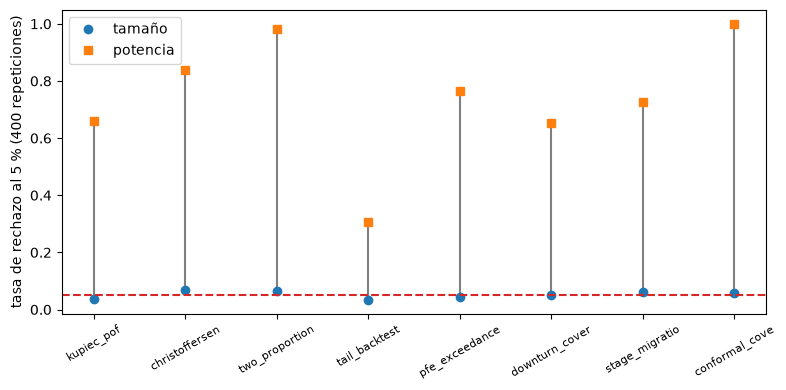

In [4]:
# Medir tamaño y potencia en vivo para ocho pruebas de otras familias con los estudios propios del motor
from riskvalidation.generators.size_studies import simulate_study, study

selected = ("market.kupiec_pof", "market.christoffersen_independence", "fair.two_proportion_z",
            "portfolio.tail_backtest", "ccr.pfe_exceedance_backtest", "lgd_ead.downturn_coverage",
            "ifrs9.stage_migration_backtest", "ml.conformal_coverage")
fig, ax = plt.subplots(figsize=(8, 4))
for position, test_id in enumerate(selected):
    item = study(test_id)
    null_run = simulate_study(item, "null", n_rep=400, seed=3)
    alt_run = simulate_study(item, "alternative", n_rep=400, seed=3)
    key = "p<0.05" if "p<0.05" in null_run.rates else next(iter(null_run.rates))
    size, power = null_run.rates[key], alt_run.rates[key]
    print(f"{test_id:36s} tamaño {size.rate:.3f} | potencia {power.rate:.3f}")
    ax.plot([position, position], [size.rate, power.rate], color="gray")
    ax.plot(position, size.rate, "o", color="tab:blue", label="tamaño" if position == 0 else None)
    ax.plot(position, power.rate, "s", color="tab:orange", label="potencia" if position == 0 else None)
ax.axhline(0.05, color="tab:red", linestyle="--")
ax.set_xticks(range(len(selected)))
ax.set_xticklabels([t.split(".")[1][:14] for t in selected], rotation=30, fontsize=8)
ax.set_ylabel("tasa de rechazo al 5 % (400 repeticiones)")
ax.legend()
fig.tight_layout()
plt.show()

Los tamaños quedan entre 0,033 y 0,068, dentro del error de Monte Carlo de 400 repeticiones en torno a 5 %, y las potencias van de 0,307 a 1,000. La prueba retrospectiva de cola de cartera es la débil, con 0,307 frente a su alternativa declarada, mientras la revisión de cobertura de aprendizaje automático y la prueba z de equidad llegan a 1,000 y 0,983. La figura muestra una cosa: una prueba no es buena o mala en abstracto, tiene un tamaño y una potencia frente a un defecto declarado, y esos dos números, que este estudio informa para cada prueba, difieren en un factor de tres entre familias.

### Paso 3: las probabilidades exactas y las tasas simuladas

Para las pruebas de conteo y los semáforos sobre años independientes los archivos llevan la probabilidad de rechazo exacta junto a la tasa simulada. La celda siguiente construye un `Rate` con los conteos de cada una de esas filas, aplica el `agrees` del motor en ambos niveles, imprime el número de comparaciones y concordancias y la mayor brecha estandarizada, y dibuja las tasas simuladas contra las exactas.

comparaciones (ambos niveles): 94 | que concuerdan: 94
mayor brecha estandarizada: 2.85


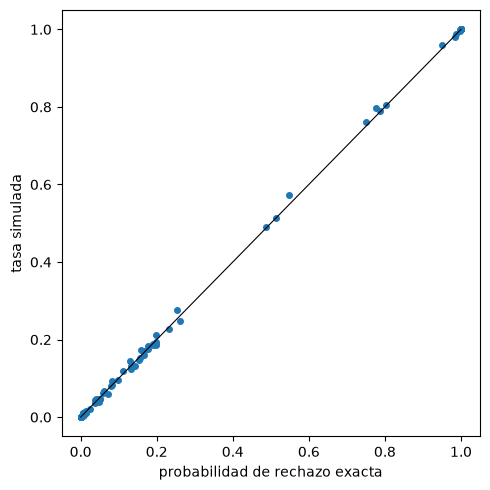

In [5]:
# Aplicar la regla agrees a cada fila que lleva una probabilidad exacta, en ambos niveles
from riskvalidation.harness.rates import Rate, agrees

compared = agreeing = 0
largest = 0.0
points = []
for n in names:
    for s in rows[n].values():
        for rule, exact in (s["exact"] or {}).items():
            c = s["rates"][rule]
            rate = Rate(c["rejections"], c["n"])
            compared += 1
            agreeing += agrees(rate, exact)
            points.append((exact, rate.rate))
            if 0.0 < exact < 1.0:
                largest = max(largest, abs(rate.rate - exact) / np.sqrt(exact * (1 - exact) / rate.n))
print("comparaciones (ambos niveles):", compared, "| que concuerdan:", agreeing)
print("mayor brecha estandarizada:", round(float(largest), 2))
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([p[0] for p in points], [p[1] for p in points], "o", markersize=4)
ax.plot([0, 1], [0, 1], color="black", linewidth=0.8)
ax.set_xlabel("probabilidad de rechazo exacta")
ax.set_ylabel("tasa simulada")
fig.tight_layout()
plt.show()

Las 94 comparaciones concuerdan, y la mayor brecha estandarizada es 2,85, bajo el criterio de 3,29. Los puntos caen sobre la diagonal de 0 a 1, incluidos los extremos donde la potencia está cerca de 1 y las colas son estrechas. Para las filas con valor exacto, la tasa del archivo no es entonces solo reproducible: es correcta, pues la cola binomial, un cálculo que no sortea ningún conjunto, llega a ella. Es la comprobación más fuerte disponible, y cubre 47 filas.

### Paso 4: filas repetidas desde sus semillas

Una tasa que no puede reproducirse no es evidencia. La celda siguiente toma una fila de cada familia, reconstruye su generador desde la configuración con las clases del motor y corre `simulate` con la semilla, la prueba y el número de repeticiones de la fila, e imprime la tasa en vivo junto a la tasa del archivo.

In [6]:
# Repetir una fila de cada familia con su semilla y escribir la tasa en vivo junto a la de la fila
from riskvalidation.generators.counts import DefaultCounts, feed_cell, feed_series
from riskvalidation.generators.drift import TwoSample
from riskvalidation.generators.ratings import GradeFrequencies, Migrations
from riskvalidation.generators.scores import BinormalScores, LogisticPortfolio
from riskvalidation.harness.run import simulate

classes = (DefaultCounts, TwoSample, GradeFrequencies, Migrations, BinormalScores, LogisticPortfolio)
CLASSES = {cls.name: cls for cls in classes}
replays = (("null", "pd.binomial@null", feed_cell()), ("miscalibration", "pd.traffic_lights@k1.5", feed_series()),
           ("clustering", "pd.spiegelhalter@rho0.1", None), ("drift", "stability.ks@s0.2", None),
           ("discrimination-decay", "disc.delong@d0.05", None), ("leakage", "stability.csi@l1", None),
           ("broken-monotonicity", "rating.migration_ztests@r2-n500", None), ("concentration", "rating.hhi@c0.5", None))
for family, key, feed in replays:
    row = rows[family][key]
    spec = families[family]["outputs"]["generators"][row["generator"]]
    generator = CLASSES[spec["name"]](**spec["config"])
    run = simulate(row["test_id"], generator, n_rep=row["n_rep"], seed=row["seed"], feed=feed)
    print(f"{family:22s} {key:34s} en vivo {run.rates['p<0.05'].rate:.4f}", end=" | ")
    print(f"de la fila {row['rates']['p<0.05']['rate']:.4f}")

null                   pd.binomial@null                   en vivo 0.0455 | de la fila 0.0455
miscalibration         pd.traffic_lights@k1.5             en vivo 0.9995 | de la fila 0.9995
clustering             pd.spiegelhalter@rho0.1            en vivo 0.3280 | de la fila 0.3280
drift                  stability.ks@s0.2                  en vivo 0.9730 | de la fila 0.9730
discrimination-decay   disc.delong@d0.05                  en vivo 0.7160 | de la fila 0.7160
leakage                stability.csi@l1                   en vivo 0.1460 | de la fila 0.1460
broken-monotonicity    rating.migration_ztests@r2-n500    en vivo 0.5550 | de la fila 0.5550
concentration          rating.hhi@c0.5                    en vivo 0.0000 | de la fila 0.0000


Las ocho tasas en vivo igualan a las de los archivos a cuatro dígitos, desde 0,0455 para la prueba binomial en la cartera nula hasta 0,9995 para los semáforos en $k = 1{,}5$, y 0,0000 para la prueba de concentración, que no puede rechazar. Los archivos los calculó la versión del motor instalada aquí, 1.0.1, así que la igualdad dice que los generadores y las pruebas se reproducen hoy en estas filas; nada dice de las filas no repetidas. La reproducibilidad es una propiedad del protocolo, y este paso la verifica donde es barato.

### Paso 5: lo que la medición halló en pruebas estándar

Una medición que no encuentra nada sería una demostración débil. La celda siguiente corre en vivo tres de los defectos que destacó la investigación: Hosmer-Lemeshow con $G-2$ grados de libertad frente a $G$, la prueba de AUC del BCE cuando el AUC de desarrollo se estimó con una muestra igual, y las reglas empíricas del PSI con muestras de 100 cuando nada cambió. Imprime el tamaño de cada uno al nivel de 5 %.

In [7]:
# Medir en vivo tres defectos de pruebas estándar: Hosmer-Lemeshow, AUC estimado, reglas del PSI
from riskvalidation.harness.run import metric_above

null_rows = rows["null"]
cfg = families["null"]["outputs"]["generators"]
logit = LogisticPortfolio(**cfg["logistic-5000"]["config"])
seed = null_rows["pd.hosmer_lemeshow@null"]["seed"]
hl_given = simulate("pd.hosmer_lemeshow", logit, n_rep=1000, seed=seed).rates["p<0.05"].rate
fitted_run = simulate("pd.hosmer_lemeshow", logit, n_rep=1000, seed=seed, test_kwargs={"fitted": True})
hl_fitted = fitted_run.rates["p<0.05"].rate
dev = BinormalScores(**cfg[null_rows["disc.auc_vs_initial@dev1"]["generator"]]["config"])
auc_dev = simulate("disc.auc_vs_initial", dev, n_rep=500, seed=11).rates["p<0.05"].rate
rules = (metric_above(0.10, "metric>0.1"), metric_above(0.25, "metric>0.25"))
psi = simulate("stability.psi", TwoSample(100, 100), n_rep=1000, seed=5, rules=rules).rates
sizes = {"HL, G": hl_given, "HL, G-2": hl_fitted, "AUC, dev. est.": auc_dev}
sizes["PSI > 0.10, n = 100"] = psi["metric>0.1"].rate
sizes["PSI > 0.25, n = 100"] = psi["metric>0.25"].rate
sizes["PSI referencia"] = psi["p<0.05"].rate
for label, value in sizes.items():
    print(f"{label:24s} tamaño al 5 % {value:.4f}")

HL, G                    tamaño al 5 % 0.0540
HL, G-2                  tamaño al 5 % 0.1200
AUC, dev. est.           tamaño al 5 % 0.1200
PSI > 0.10, n = 100      tamaño al 5 % 0.8620
PSI > 0.25, n = 100      tamaño al 5 % 0.2170
PSI referencia           tamaño al 5 % 0.0720


Hosmer-Lemeshow rechaza un modelo correcto el 0,1200 de las veces con $G-2$ grados de libertad y el 0,0540 con $G$. La prueba de AUC del BCE rechaza el 0,1200 cuando el AUC de desarrollo se estimó con una muestra igual. Con muestras de 100 y nada cambiado, la regla del PSI sobre 0,10 se activa el 0,862 de las veces y la regla sobre 0,25 el 0,217, frente a 0,072 de la referencia chi-cuadrado. Son propiedades de las pruebas, no de un banco, y ninguna podría conocerse sin correr la prueba sobre datos de verdad conocida.

### Paso 6: dos defectos más, uno de ellos exacto

La prueba de Jeffreys tiene un tamaño exacto al nivel de 1 % que `rejection_probability` devuelve sin simulación, y el estadístico de concentración del BCE puede evaluarse sobre cada redistribución de los grados con `rating_hhi` y `concentrate`. La celda siguiente imprime ambos y dibuja todos los tamaños del paso anterior como barras contra el 5 % nominal.

Jeffreys, tamaño exacto al 1 %: 0.01383
concentración del BCE, mayor estadístico: 1.0913
valor crítico al 5 %: 1.6449


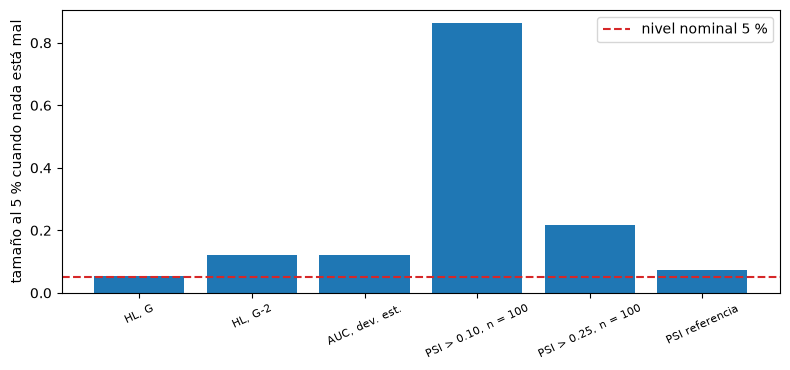

In [8]:
# Tamaño exacto de Jeffreys al 1 %, mayor estadístico de concentración del BCE, y los tamaños dibujados
from riskvalidation.generators.ratings import concentrate
from riskvalidation.harness.exact import rejection_probability
from riskvalidation.validation.rating_system import rating_hhi

jeffreys = rejection_probability("pd.jeffreys", 1000, 0.01, 0.01)["probability"]
initial = np.array(families["concentration"]["outputs"]["generators"]["grades-10-c0.5"]["config"]["initial"])
largest_hhi = max(rating_hhi(concentrate(initial, s), initial).statistic for s in np.linspace(0.0, 1.0, 101))
print("Jeffreys, tamaño exacto al 1 %:", round(jeffreys, 5))
print("concentración del BCE, mayor estadístico:", round(float(largest_hhi), 4))
print("valor crítico al 5 %:", round(float(stats.norm.isf(0.05)), 4))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(range(len(sizes)), list(sizes.values()), color="tab:blue")
ax.axhline(0.05, color="tab:red", linestyle="--", label="nivel nominal 5 %")
ax.set_xticks(range(len(sizes)))
ax.set_xticklabels(list(sizes), rotation=25, fontsize=8)
ax.set_ylabel("tamaño al 5 % cuando nada está mal")
ax.legend()
fig.tight_layout()
plt.show()

La prueba de Jeffreys tiene un tamaño exacto de 0,01383 al nivel de 1 % para 1.000 deudores con una PD de 1 %. El estadístico de concentración alcanza su máximo de 1,0913 sobre cada redistribución de los diez grados, bajo el 1,6449 que necesita al 5 %, así que la prueba no puede rechazar. Las barras ponen lado a lado los seis tamaños del paso anterior, y varios están muy sobre la línea roja mientras solo la referencia de Hosmer-Lemeshow con $G$ y la referencia chi-cuadrado están cerca de ella. Una batería cuyos miembros difieren tanto no puede leerse con un solo umbral.

### Paso 7: el registro de hallazgos

Cada archivo lleva un registro de hallazgos, cada uno con una severidad (S2 la más grave, S4 la menor), un estado y las filas de simulación que lo evidencian, además de algunos especímenes del equipo rojo (`F-RED`) que apuntan a generadores y no a filas. La celda siguiente cuenta los hallazgos del registro por severidad y estado, revisa que cada fila de evidencia exista y lista los seis primeros.

In [9]:
# Contar los hallazgos del registro por severidad y estado y revisar que cada uno nombre una fila existente
keys = {key for n in names for key in rows[n]}
everything = [(n, f) for n in names for f in families[n]["findings"]]
register = [(n, f) for n, f in everything if not f["id"].startswith("F-RED")]
print("hallazgos en los archivos:", len(everything))
specimens = len(everything) - len(register)
print("especímenes del equipo rojo:", specimens)
by_severity = Counter(f["severity"] for _, f in register)
by_status = Counter(f["status"] for _, f in register)
print("hallazgos del registro:", len(register), "|", "por severidad:", dict(sorted(by_severity.items())))
status_name = {"accepted": "aceptado", "closed": "cerrado", "open": "abierto"}
print("por estado:", {status_name[k]: v for k, v in sorted(by_status.items())})
named = [item.split(":", 1)[-1] for _, f in register for item in f["evidence"]]
print("filas de evidencia nombradas:", len(named), "| que existen:", sum(1 for key in named if key in keys))
for n, f in register[:6]:
    print(f"{f['severity']} {status_name[f['status']]:9s} {f['id']:20s} {f['title'][LANG][:60]}")

hallazgos en los archivos: 31
especímenes del equipo rojo: 8
hallazgos del registro: 23 | por severidad: {'S2': 10, 'S3': 7, 'S4': 6}
por estado: {'aceptado': 17, 'cerrado': 4, 'abierto': 2}
filas de evidencia nombradas: 53 | que existen: 53
S2 cerrado   F-HL-DOF             Hosmer-Lemeshow con G − 2 grados de libertad sobrerrechaza e
S3 aceptado  F-NORMAL-SIZE        La prueba normal en cinco años rechaza sobre su nivel, como 
S3 aceptado  F-TL-TIES            El tamaño del semáforo depende del color de un año con exact
S3 aceptado  F-CHI2-THIN          La prueba chi-cuadrado por grados excede su nivel cuando un 
S2 cerrado   F-AUC-INIT           La prueba de AUC del BCE trata el AUC de desarrollo como con
S4 aceptado  F-JEFFREYS-DISCRETE  La prueba de Jeffreys es bayesiana; sobre un conteo discreto


Los archivos tienen 31 hallazgos, 8 de ellos especímenes del equipo rojo, lo que deja 23 en el registro: 10 de severidad S2, 7 de S3 y 6 de S4, con 17 aceptados como propiedades de las pruebas, 4 cerrados y 2 abiertos. Las 53 filas de evidencia nombradas existen. Las primeras entradas repiten los defectos de este notebook, los grados de libertad de Hosmer-Lemeshow, el tamaño de la prueba normal, la regla de empate de los semáforos y la prueba de Jeffreys sobre un conteo discreto. La medición halló defectos en las pruebas para las que se construyó, que es la mejor evidencia de que mide algo.

## Resultados

**Respuesta:** Sí, dentro de un alcance declarado. Las ocho familias reúnen 256 simulaciones y 651.000 repeticiones de 42 pruebas, 537 tasas cada una con su error de Monte Carlo, y 47 filas cuya tasa simulada concuerda con una probabilidad exacta en las 94 comparaciones, con una mayor brecha estandarizada de 2,85. Ocho filas se repiten desde sus semillas hasta la misma tasa. La medición halló defectos que ni el estándar ni las herramientas informan: Hosmer-Lemeshow con $G-2$ grados de libertad rechaza un modelo correcto el 0,1200 de las veces, la prueba de AUC del BCE el 0,1200, la regla del PSI sobre 0,10 se activa el 0,862 de las veces con muestras de 100 y nada cambiado, la prueba de Jeffreys tiene un tamaño exacto de 0,01383 al 1 %, y el estadístico de concentración alcanza 1,0913, bajo el 1,6449 que necesita.

- **La afirmación es menor que «cada prueba bajo cada defecto», y se enuncia a su tamaño verdadero.** 25 de las 42 pruebas tienen una fila de tamaño y ninguna de potencia, de modo que BS-1 afirma el tamaño de todas y la potencia solo de las que tienen un defecto plantado.
- **La potencia es dispar, y esa disparidad es el hallazgo.** En la medición en vivo las potencias van de 0,307 para la prueba retrospectiva de cola de cartera a 1,000 para la revisión de cobertura de aprendizaje automático.
- **El registro tiene 23 hallazgos:** 10 de S2, 7 de S3 y 6 de S4, con 17 aceptados, 4 cerrados y 2 abiertos.

Lo que la afirmación no dice: que una tasa se mantiene fuera del generador y de la escalera en que se midió, pues una escalera es una decisión de diseño y la potencia frente a ella no es la probabilidad de detectar el problema de un banco real; que algún tamaño o potencia implique un umbral regulatorio; ni que ningún otro trabajo mida lo mismo, pues «más allá del estado del arte» es relativo a un relevamiento de documentación hecho en octubre de 2026 (NO VERIFICADO más allá de lo que leyó).

## Resumen

- BS-1 se apoya en 256 simulaciones y 651.000 repeticiones de 42 pruebas, 537 tasas cada una con su error de Monte Carlo, 47 filas con una probabilidad exacta y 148 generadores cuya verdad está escrita.
- Los estudios en vivo del motor miden tamaño y potencia de pruebas de otras familias, con potencias de 0,307 a 1,000.
- Las 94 comparaciones de una tasa simulada con su probabilidad exacta concuerdan, y ocho filas se repiten desde sus semillas.
- La medición halló defectos en pruebas estándar, evidenciados por las cifras anteriores y por un registro de 23 hallazgos.
- Enunciada a su tamaño verdadero, la afirmación es el tamaño de cada prueba y la potencia de las que tienen un defecto plantado, sobre los generadores y escaleras medidos.

**Qué probar después.** Elige otra prueba de los `STUDIES` de `riskvalidation.generators.size_studies`, corre su nula y su alternativa como en el paso 2 y agrégala a la figura.

## Referencias

- Morris, T. P., White, I. R. y Crowther, M. J. (2019), Using simulation studies to evaluate statistical methods, Statistics in Medicine 38(11). https://doi.org/10.1002/sim.8086
- Brown, L. D., Cai, T. T. y DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revised): la conclusión sobre las pruebas de calibración (páginas 41 a 42). https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- Yurdakul, B. y Naranjo, J. (2020), Statistical properties of the population stability index, Journal of Risk Model Validation 14(4). https://doi.org/10.21314/JRMV.2020.227
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk. https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Demler, O. V., Pencina, M. J. y D'Agostino, R. B. Sr (2012), Misuse of DeLong test to compare AUCs for nested models, Statistics in Medicine 31(23). https://doi.org/10.1002/sim.5328
- Hosmer, D. W. y Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- Los dossiers de investigación del producto (registros de CAOS_MANAGE, `wip/contraste/`): 06 (secciones A.3 y D) y 12 (secciones 1 a 6); `docs/design/features/c22-validator/requirements.md` y `tests/test_c22.py` de este repositorio, los requisitos y las pruebas que sostienen las mediciones.